In [230]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
import statsmodels.api as sm
from scipy.stats.contingency import association
%matplotlib inline

In [19]:
# import data
df = pd.read_csv('/Users/reppmazc/Downloads/amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

### 1. Crosstab Analysis:
- Create a crosstab between the product category and the isBestSeller status.
- Are there categories where being a best-seller is more prevalent?
Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

### 2. Statistical Tests:
- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

### 3. Visualizations:
- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [56]:
# Part1: 1. Crosstab
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [58]:
# Part1: 2. Chi-square
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab) # only takes crosstab not vars separately
chi2_statistic.round(), chi2_p_value.round()

(36540.0, 0.0)

In [60]:
# Part1: 2. cramers V
association(crosstab, method="cramer")

0.1222829439760564

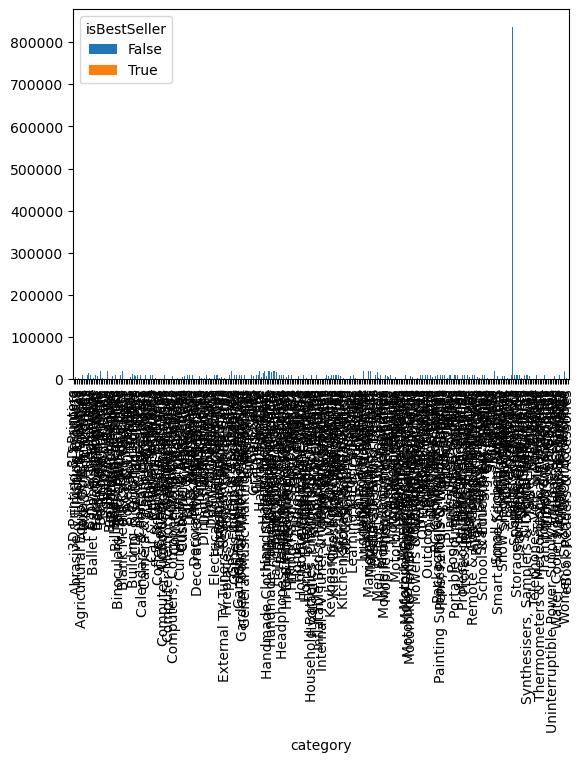

In [68]:
# Part1: 3.
crosstab.plot(kind = 'bar', stacked = True)
#plt.tight_layout()
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

### 0. Preliminary Step: Remove outliers in product prices.
- For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [98]:
# Part 2: 0
def remove_outliers(dataframe, col):
    Q1 = dataframe[col].quantile(0.25)
    Q3 = dataframe[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + (1.5 * IQR)
    lower = Q1 - (1.5 * IQR)
    df_filtered = dataframe[(dataframe[col] <= upper) & (dataframe[col] >= lower)]
    print(f'lower bound: {lower}')
    print(f'upper bound: {upper}')
    return df_filtered

cleaned = remove_outliers(df, 'price')
cleaned

print(f'Nr of outliers: {df.shape[0] - cleaned.shape[0]}')

lower bound: -44.01
upper bound: 99.99000000000001
Nr of outliers: 327688


### Part 2: 1. Violin Plots:
- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

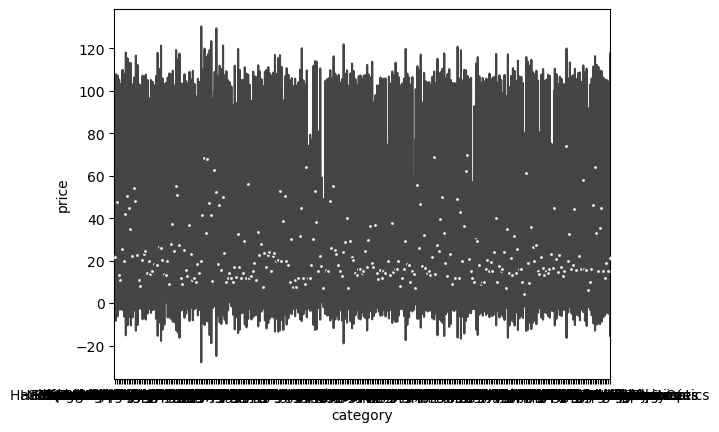

In [117]:
sns.violinplot(data = cleaned, x = 'category', y = 'price')
plt.show()

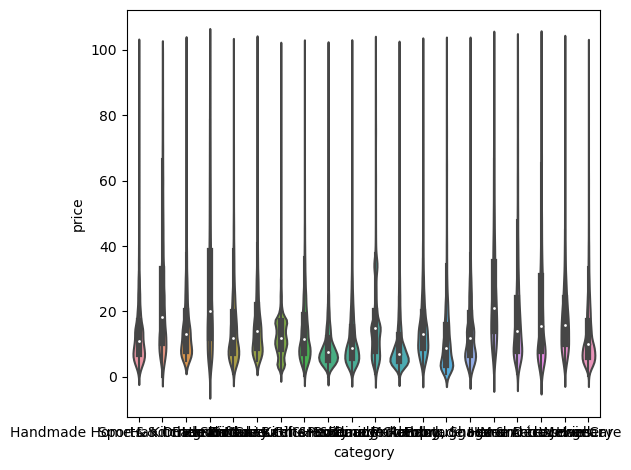

In [127]:
filtered = cleaned['category'].value_counts().index[:20]
cleaned_reduced = cleaned[cleaned['category'].isin(filtered)]
sns.violinplot(data = cleaned_reduced, x = 'category', y = 'price')
plt.tight_layout()
plt.show()

In [163]:
grouped = cleaned.groupby('category')['price'].median().sort_values(ascending = False)
grouped

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

### Part 2: 2. Bar Charts:
- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

<Axes: xlabel='category'>

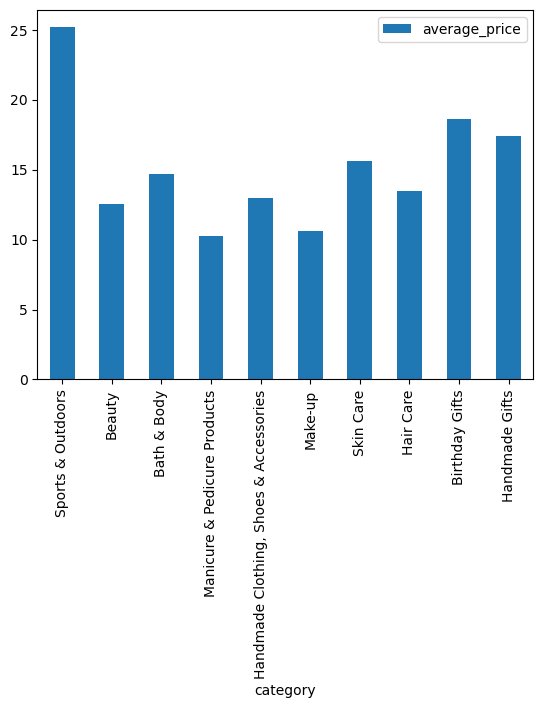

In [173]:
category_stats = cleaned.groupby('category').agg(count=('category', 'size'),
                                                 average_price=('price', 'mean'))
top_10 = category_stats.sort_values(by='count', ascending=False).head(10)
top_10.plot(kind = 'bar', y = 'average_price')

In [175]:
grouped = cleaned.groupby('category')['price'].mean().sort_values(ascending = False)
grouped

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

### Part 2: 3. Box Plots:
- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

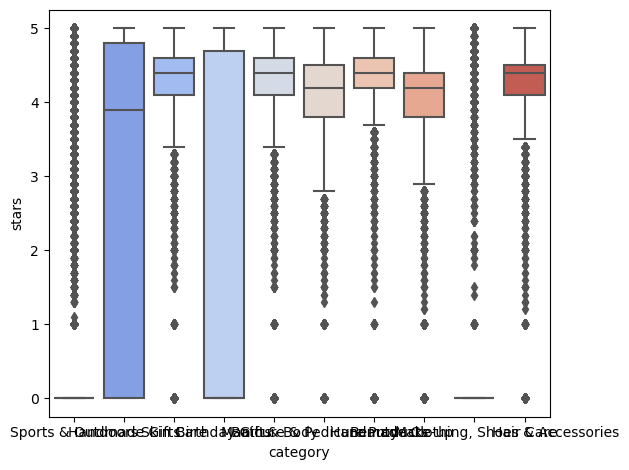

In [190]:
top_cat = cleaned.groupby('category').size().sort_values(ascending=False).head(10).index
filtered_data = cleaned[cleaned['category'].isin(top_cat)]

sns.boxplot(x='category', y='stars', data=filtered_data, palette="coolwarm")
plt.tight_layout()
plt.show()

In [192]:
grouped = cleaned.groupby('category')['stars'].median().sort_values(ascending = False)
grouped

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

### 1. Correlation Coefficients:
- Calculate the correlation coefficient between price and stars.
- Is there a significant correlation between product price and its rating?

In [218]:
correlation = cleaned['price'].corr(cleaned['stars'])
correlation

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


-0.0776729987818095

In [220]:
correlation = cleaned['price'].corr(cleaned['stars'], method = 'spearman')
correlation

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


-0.06679697280767981

### Part 3: 2. Visualizations:
- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

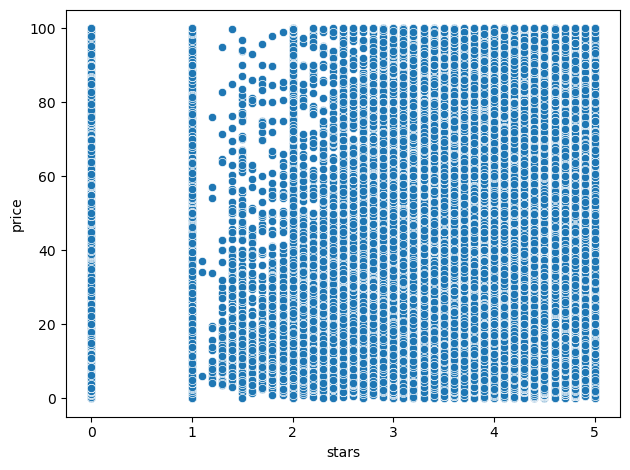

In [202]:
sns.scatterplot(data=cleaned, x='stars', y='price')
plt.tight_layout()
plt.show()

<Axes: >

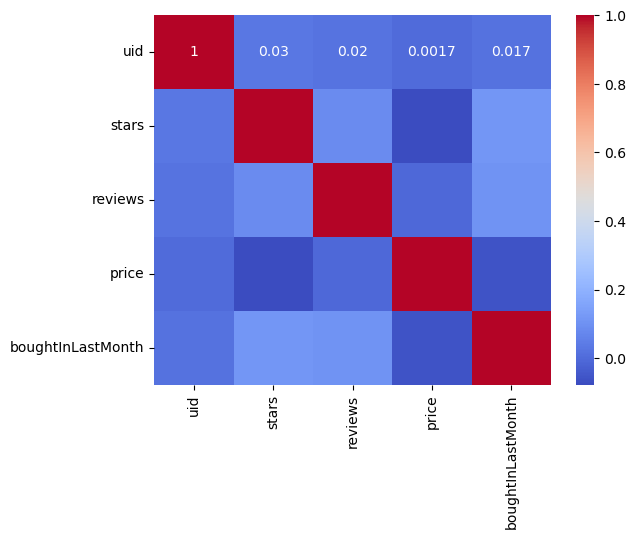

In [226]:
numerical_cols = cleaned.select_dtypes(include=['number'])
correlation_matrix = numerical_cols.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

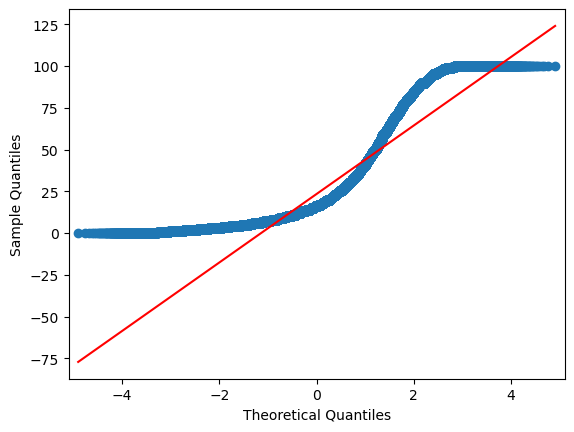

In [ ]:
sm.qqplot(cleaned['price'], line='s')